# 04 — Final Evaluation, Explainability & Submission

**Objective.** Evaluate the saved pipeline **once** on the untouched validation
split, explain its predictions, persist metrics/figures for the Streamlit UI, and
produce a submission for the unlabelled `test.csv`.

No metric here is claimed on `test.csv` — it has no labels.

In [1]:
import json, joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
    average_precision_score, f1_score, recall_score, precision_score, accuracy_score,
    roc_curve, precision_recall_curve)
from sklearn.inspection import permutation_importance
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()), Path.cwd())
RAW = ROOT / "data" / "raw" / "binaryclassificationwithabankchurndataset"
PROC = ROOT / "data" / "processed"
MODELS = ROOT / "models"
FIG = MODELS / "figures"
for d in (PROC, FIG):
    d.mkdir(parents=True, exist_ok=True)
print("project root:", ROOT)

project root: /home/sabina/portfolio/creditscoring


In [2]:
pipe = joblib.load(MODELS / "pipeline.pkl")
val = pd.read_csv(PROC / "val.csv")
Xv = val.drop(columns=["Exited"]); yv = val["Exited"].astype(int)

THRESHOLD = 0.50
proba = pipe.predict_proba(Xv)[:, 1]
pred = (proba >= THRESHOLD).astype(int)

metrics = {
    "accuracy": accuracy_score(yv, pred),
    "precision": precision_score(yv, pred, zero_division=0),
    "recall_churn": recall_score(yv, pred),
    "f1": f1_score(yv, pred),
    "roc_auc": roc_auc_score(yv, proba),
    "pr_auc": average_precision_score(yv, proba),
}
print(pd.Series(metrics).round(4).to_string())
print("\n", classification_report(yv, pred, target_names=["stayed", "churn"]))

accuracy        0.8600
precision       0.6033
recall_churn    0.8588
f1              0.7087
roc_auc         0.9338
pr_auc          0.8264

               precision    recall  f1-score   support

      stayed       0.96      0.86      0.91      2405
       churn       0.60      0.86      0.71       595

    accuracy                           0.86      3000
   macro avg       0.78      0.86      0.81      3000
weighted avg       0.89      0.86      0.87      3000



## Confusion matrix, ROC and PR curves

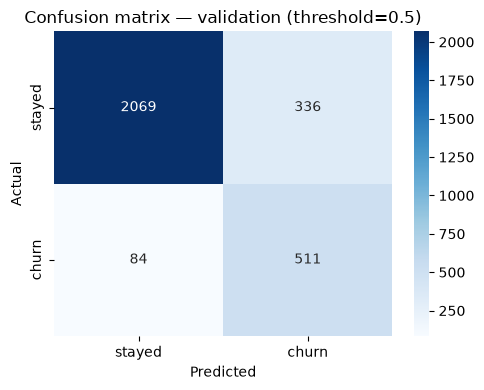

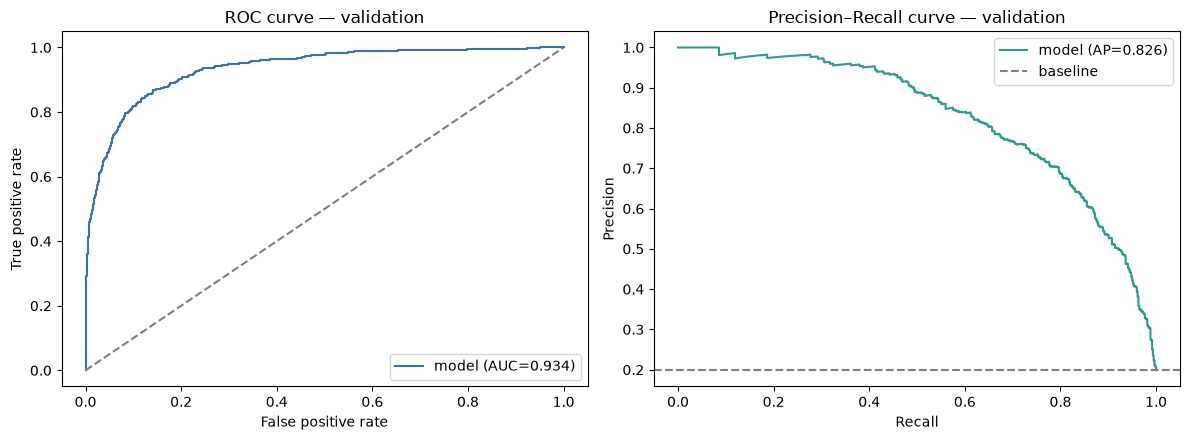

In [3]:
cm = confusion_matrix(yv, pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["stayed", "churn"], yticklabels=["stayed", "churn"])
ax.set_title(f"Confusion matrix — validation (threshold={THRESHOLD})")
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.savefig(FIG / "confusion_matrix.png", dpi=120); plt.show()

fpr, tpr, _ = roc_curve(yv, proba)
pr, rc, _ = precision_recall_curve(yv, proba)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, color="#3b6fb6", label=f"model (AUC={metrics['roc_auc']:.3f})")
axes[0].plot([0,1], [0,1], "--", color="grey"); axes[0].set_title("ROC curve — validation")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].legend()
axes[1].plot(rc, pr, color="#2a9d8f", label=f"model (AP={metrics['pr_auc']:.3f})")
axes[1].axhline(yv.mean(), ls="--", color="grey", label="baseline")
axes[1].set_title("Precision–Recall curve — validation")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "roc_pr.png", dpi=120); plt.show()

## Explainability — permutation importance

Model-agnostic importance measured as the drop in validation ROC-AUC when a single
original feature is shuffled. Larger drops mean the model relies more on that feature.

,feature,importance,std
6,NumOfProducts,0.1389,0.0044
3,Age,0.1014,0.0060
5,Balance,0.0291,0.0024
8,IsActiveMember,0.0175,0.0021
1,Geography,0.0145,0.0011
2,Gender,0.0070,0.0014
0,CreditScore,0.0031,0.0002
9,EstimatedSalary,0.0008,0.0007
4,Tenure,0.0003,0.0003
7,HasCrCard,-0.0001,0.0002


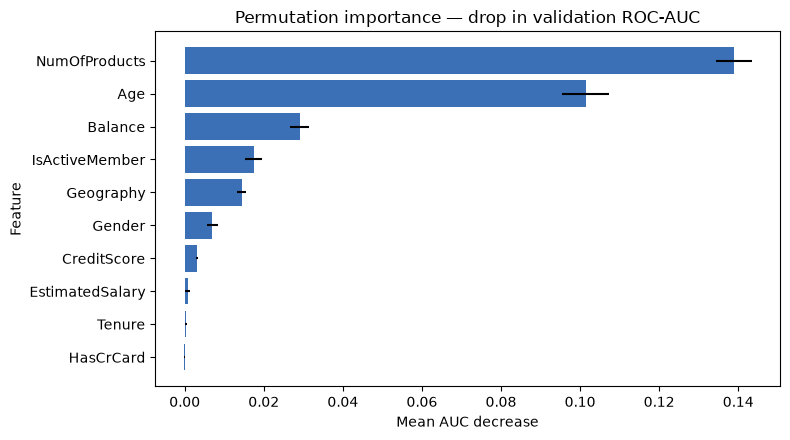

In [4]:
result = permutation_importance(pipe, Xv, yv, scoring="roc_auc",
                                n_repeats=8, random_state=42, n_jobs=-1)
imp = pd.DataFrame({"feature": Xv.columns,
                    "importance": result.importances_mean,
                    "std": result.importances_std}).sort_values("importance", ascending=False)
display(imp.round(4))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp["feature"][::-1], imp["importance"][::-1],
        xerr=imp["std"][::-1], color="#3b6fb6")
ax.set_title("Permutation importance — drop in validation ROC-AUC")
ax.set_xlabel("Mean AUC decrease"); ax.set_ylabel("Feature")
plt.tight_layout(); plt.savefig(FIG / "importance.png", dpi=120); plt.show()

## Persist metadata for the UI

All numbers consumed by the Streamlit app come from this file — the UI never
hardcodes metrics.

In [5]:
metadata = {
    "feature_order": Xv.columns.tolist(),
    "threshold": THRESHOLD,
    "train_rows": int(len(pd.read_csv(PROC / "train.csv"))),
    "val_rows": int(len(val)),
    "churn_rate": float(pd.read_csv(RAW / "train.csv")["Exited"].mean()),
    "metrics": {k: round(float(v), 4) for k, v in metrics.items()},
    "confusion_matrix": cm.tolist(),
    "importance": imp.round(4).to_dict(orient="records"),
}
with open(MODELS / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print(json.dumps(metadata["metrics"], indent=2))

{
  "accuracy": 0.86,
  "precision": 0.6033,
  "recall_churn": 0.8588,
  "f1": 0.7087,
  "roc_auc": 0.9338,
  "pr_auc": 0.8264
}


## Submission for the unlabelled test set

`test.csv` has no `Exited` column, so we only output probabilities. Applying the
exact same column drop as training guarantees feature parity.

In [6]:
test = pd.read_csv(RAW / "test.csv")
X_test = test.drop(columns=["id", "CustomerId", "Surname"])
sub = pd.read_csv(RAW / "sample_submission.csv")
sub["Exited"] = pipe.predict_proba(X_test)[:, 1]
sub.to_csv(ROOT / "submission.csv", index=False)
print("Wrote submission.csv:", sub.shape)
display(sub.head())

Wrote submission.csv: (10000, 2)


,id,Exited
0,15000,0.080812
1,15001,0.352846
2,15002,0.129888
3,15003,0.324868
4,15004,0.019568


**Outcome.** Validation metrics, confusion matrix, ROC/PR and importance charts are
saved under `models/` and consumed by the Streamlit app; `submission.csv` is written
for the unlabelled test set. End of the research lifecycle.